# EDA Mini Challenge

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

df = pd.read_csv("data.csv", encoding="cp1252")

print("Dataset loaded successfully!")
print("Shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Shape: (541909, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,12/1/2010 8:26,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,12/1/2010 8:26,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,12/1/2010 8:26,3.39,17850.0,United Kingdom


## Understand the dataset
Before analyzing the values, understand what the dataset represents.

In [2]:
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

print("\nColumn names:")
print(df.columns.tolist())

print("\nFirst five rows:")
display(df.head())

print("\nLast five rows:")
display(df.tail())

print("\nRandom five rows:")
display(df.sample(min(5, len(df)), random_state=42))

Rows: 541909
Columns: 8

Column names:
['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']

First five rows:


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,12/1/2010 8:26,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,12/1/2010 8:26,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,12/1/2010 8:26,3.39,17850.0,United Kingdom



Last five rows:


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
541904,581587,22613,PACK OF 20 SPACEBOY NAPKINS,12,12/9/2011 12:50,0.85,12680.0,France
541905,581587,22899,CHILDREN'S APRON DOLLY GIRL,6,12/9/2011 12:50,2.10,12680.0,France
541906,581587,23254,CHILDRENS CUTLERY DOLLY GIRL,4,12/9/2011 12:50,4.15,12680.0,France
541907,581587,23255,CHILDRENS CUTLERY CIRCUS PARADE,4,12/9/2011 12:50,4.15,12680.0,France
541908,581587,22138,BAKING SET 9 PIECE RETROSPOT,3,12/9/2011 12:50,4.95,12680.0,France



Random five rows:


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
209268,555200,71459,HANGING JAM JAR T-LIGHT HOLDER,24,6/1/2011 12:05,0.85,17315.0,United Kingdom
207108,554974,21128,GOLD FISHING GNOME,4,5/27/2011 17:14,6.95,14031.0,United Kingdom
167085,550972,21086,SET/6 RED SPOTTY PAPER CUPS,4,4/21/2011 17:05,0.65,14031.0,United Kingdom
471836,576652,22812,PACK 3 BOXES CHRISTMAS PANETTONE,3,11/16/2011 10:39,1.95,17198.0,United Kingdom
115865,546157,22180,RETROSPOT LAMP,2,3/10/2011 8:40,9.95,13502.0,United Kingdom


## Inspect the structure and identify data types
Use info() and dtypes to understand how Python interprets each column.

In [3]:
print("Dataset information:")
df.info()

print("\nData types:")
print(df.dtypes)

print("\nUnique values per column:")
print(df.nunique(dropna=True))

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   InvoiceNo    541909 non-null  str    
 1   StockCode    541909 non-null  str    
 2   Description  540455 non-null  str    
 3   Quantity     541909 non-null  int64  
 4   InvoiceDate  541909 non-null  str    
 5   UnitPrice    541909 non-null  float64
 6   CustomerID   406829 non-null  float64
 7   Country      541909 non-null  str    
dtypes: float64(2), int64(1), str(5)
memory usage: 67.3 MB

Data types:
InvoiceNo          str
StockCode          str
Description        str
Quantity         int64
InvoiceDate        str
UnitPrice      float64
CustomerID     float64
Country            str
dtype: object

Unique values per column:
InvoiceNo      25900
StockCode       4070
Description     4223
Quantity         722
InvoiceDate    23260
UnitPrice       1630
CustomerID      4372
Countr

## Identify missing values
Missing data can affect calculations, visualizations, and future Machine Learning models.

In [4]:
missing_report = pd.DataFrame({
    "Missing Count": df.isna().sum(),
    "Missing Percentage": (df.isna().mean() * 100).round(2)
})

missing_report = missing_report.sort_values(
    "Missing Percentage",
    ascending=False
)

display(missing_report)

,Missing Count,Missing Percentage
CustomerID,135080,24.93
Description,1454,0.27
StockCode,0,0.00
InvoiceNo,0,0.00
Quantity,0,0.00
InvoiceDate,0,0.00
UnitPrice,0,0.00
Country,0,0.00


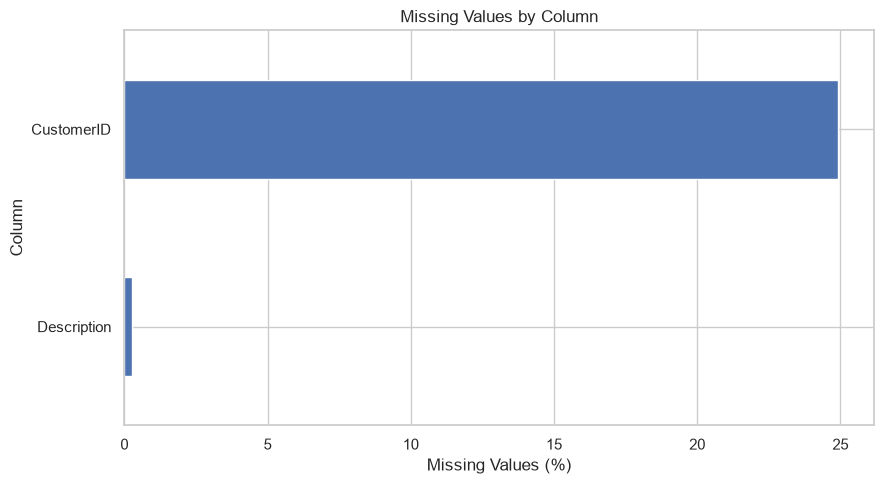

In [6]:
missing_percent = df.isna().mean().mul(100)
missing_percent = missing_percent[missing_percent > 0].sort_values()

if len(missing_percent) > 0:
    missing_percent.plot(kind="barh", figsize=(9, 5))
    plt.title("Missing Values by Column")
    plt.xlabel("Missing Values (%)")
    plt.ylabel("Column")
    plt.tight_layout()
    plt.show()
else:
    print("No missing values found.")

## Identify duplicate records
Duplicates can inflate counts and distort summary statistics.

In [7]:
duplicate_count = df.duplicated().sum()

print("Exact duplicate rows:", duplicate_count)
print(
    "Duplicate percentage:",
    round(df.duplicated().mean() * 100, 2),
    "%"
)

display(df[df.duplicated(keep=False)].head(10))

Exact duplicate rows: 5268
Duplicate percentage: 0.97 %


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
485,536409,22111,SCOTTIE DOG HOT WATER BOTTLE,1,12/1/2010 11:45,4.95,17908.0,United Kingdom
489,536409,22866,HAND WARMER SCOTTY DOG DESIGN,1,12/1/2010 11:45,2.10,17908.0,United Kingdom
494,536409,21866,UNION JACK FLAG LUGGAGE TAG,1,12/1/2010 11:45,1.25,17908.0,United Kingdom
517,536409,21866,UNION JACK FLAG LUGGAGE TAG,1,12/1/2010 11:45,1.25,17908.0,United Kingdom
521,536409,22900,SET 2 TEA TOWELS I LOVE LONDON,1,12/1/2010 11:45,2.95,17908.0,United Kingdom
527,536409,22866,HAND WARMER SCOTTY DOG DESIGN,1,12/1/2010 11:45,2.10,17908.0,United Kingdom
537,536409,22900,SET 2 TEA TOWELS I LOVE LONDON,1,12/1/2010 11:45,2.95,17908.0,United Kingdom
539,536409,22111,SCOTTIE DOG HOT WATER BOTTLE,1,12/1/2010 11:45,4.95,17908.0,United Kingdom
548,536412,22327,ROUND SNACK BOXES SET OF 4 SKULLS,1,12/1/2010 11:49,2.95,17920.0,United Kingdom
555,536412,22327,ROUND SNACK BOXES SET OF 4 SKULLS,1,12/1/2010 11:49,2.95,17920.0,United Kingdom


## Analyze numerical features
Numerical analysis helps you understand the center, spread, and range of values.

In [8]:
numeric_df = df.select_dtypes(include="number")

print("Numerical columns:")
print(numeric_df.columns.tolist())

display(numeric_df.describe().T)

Numerical columns:
['Quantity', 'UnitPrice', 'CustomerID']


,count,mean,std,min,25%,50%,75%,max
Quantity,541909.0,9.552250,218.081158,-80995.00,1.00,3.00,10.00,80995.0
UnitPrice,541909.0,4.611114,96.759853,-11062.06,1.25,2.08,4.13,38970.0
CustomerID,406829.0,15287.690570,1713.600303,12346.00,13953.00,15152.00,16791.00,18287.0


In [9]:
numeric_summary = pd.DataFrame({
    "Mean": numeric_df.mean(),
    "Median": numeric_df.median(),
    "Variance": numeric_df.var(),
    "Standard Deviation": numeric_df.std(),
    "Skewness": numeric_df.skew(),
    "Missing Values": numeric_df.isna().sum()
})

display(numeric_summary.round(3))

,Mean,Median,Variance,Standard Deviation,Skewness,Missing Values
Quantity,9.552,3.00,47559.391,218.081,-0.264,0
UnitPrice,4.611,2.08,9362.469,96.760,186.507,0
CustomerID,15287.691,15152.00,2936426.000,1713.600,0.030,135080


## Analyze categorical features
Categorical analysis shows which groups occur most frequently and whether some categories are rare.

In [10]:
categorical_columns = df.select_dtypes(
    include=["object", "category", "string"]
).columns

print("Categorical columns:", categorical_columns.tolist())

for column in categorical_columns:
    print(f"\n--- {column} ---")
    print("Unique categories:", df[column].nunique(dropna=True))
    display(df[column].value_counts(dropna=False).head(10))

Categorical columns: ['InvoiceNo', 'StockCode', 'Description', 'InvoiceDate', 'Country']

--- InvoiceNo ---
Unique categories: 25900


InvoiceNo
573585    1114
581219     749
581492     731
580729     721
558475     705
579777     687
581217     676
537434     675
580730     662
538071     652
Name: count, dtype: int64


--- StockCode ---
Unique categories: 4070


StockCode
85123A    2313
22423     2203
85099B    2159
47566     1727
20725     1639
84879     1502
22720     1477
22197     1476
21212     1385
20727     1350
Name: count, dtype: int64


--- Description ---
Unique categories: 4223


Description
WHITE HANGING HEART T-LIGHT HOLDER    2369
REGENCY CAKESTAND 3 TIER              2200
JUMBO BAG RED RETROSPOT               2159
PARTY BUNTING                         1727
LUNCH BAG RED RETROSPOT               1638
ASSORTED COLOUR BIRD ORNAMENT         1501
SET OF 3 CAKE TINS PANTRY DESIGN      1473
NaN                                   1454
PACK OF 72 RETROSPOT CAKE CASES       1385
LUNCH BAG  BLACK SKULL.               1350
Name: count, dtype: int64


--- InvoiceDate ---
Unique categories: 23260


InvoiceDate
10/31/2011 14:41    1114
12/8/2011 9:28       749
12/9/2011 10:03      731
12/5/2011 17:24      721
6/29/2011 15:58      705
11/30/2011 15:13     687
12/8/2011 9:20       676
12/6/2010 16:57      675
12/5/2011 17:28      662
12/9/2010 14:09      652
Name: count, dtype: int64


--- Country ---
Unique categories: 38


Country
United Kingdom    495478
Germany             9495
France              8557
EIRE                8196
Spain               2533
Netherlands         2371
Belgium             2069
Switzerland         2002
Portugal            1519
Australia           1259
Name: count, dtype: int64

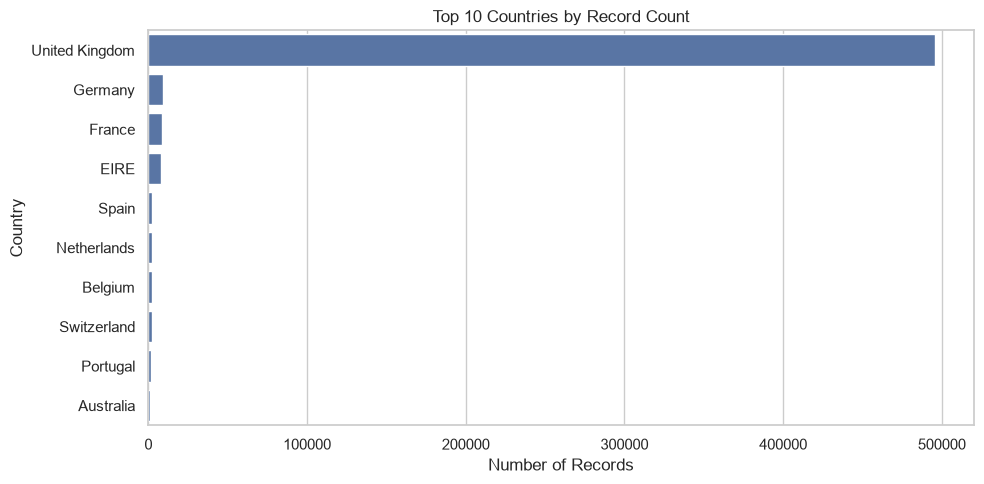

In [11]:
country_counts = df["Country"].value_counts().head(10)

plt.figure(figsize=(10, 5))
sns.barplot(
    x=country_counts.values,
    y=country_counts.index
)

plt.title("Top 10 Countries by Record Count")
plt.xlabel("Number of Records")
plt.ylabel("Country")
plt.tight_layout()
plt.show()

## Detect potential outliers
Outliers are observations that lie unusually far from the majority of values. They may represent errors, genuine unusual events, or valid business activity.



In [12]:
for column in ["Quantity", "UnitPrice"]:
    values = df[column].dropna()

    q1 = values.quantile(0.25)
    q3 = values.quantile(0.75)
    iqr = q3 - q1

    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr

    outlier_mask = (
        (values < lower_bound) |
        (values > upper_bound)
    )

    print(f"\nFeature: {column}")
    print("Lower bound:", lower_bound)
    print("Upper bound:", upper_bound)
    print("Potential outliers:", int(outlier_mask.sum()))
    print(
        "Percentage:",
        round(outlier_mask.mean() * 100, 2),
        "%"
    )


Feature: Quantity
Lower bound: -12.5
Upper bound: 23.5
Potential outliers: 58619
Percentage: 10.82 %

Feature: UnitPrice
Lower bound: -3.0700000000000003
Upper bound: 8.45
Potential outliers: 39627
Percentage: 7.31 %


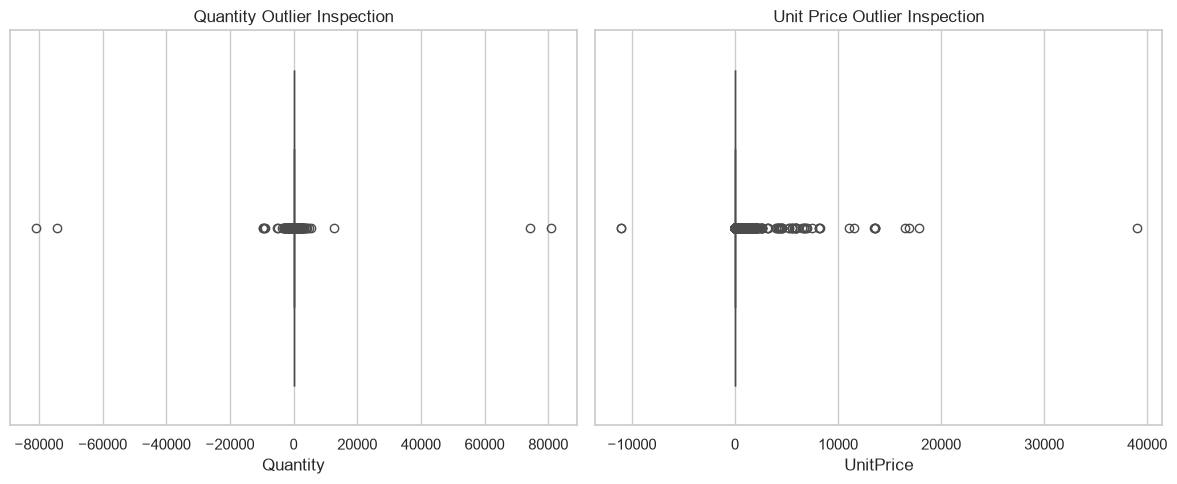

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.boxplot(data=df, x="Quantity", ax=axes[0])
axes[0].set_title("Quantity Outlier Inspection")

sns.boxplot(data=df, x="UnitPrice", ax=axes[1])
axes[1].set_title("Unit Price Outlier Inspection")

plt.tight_layout()
plt.show()

## Analyze distributions
A distribution shows how frequently different numerical values occur.

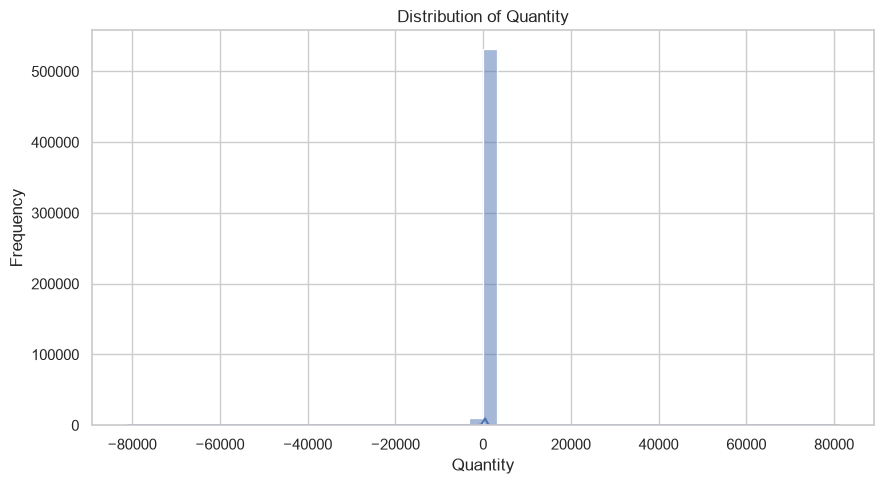

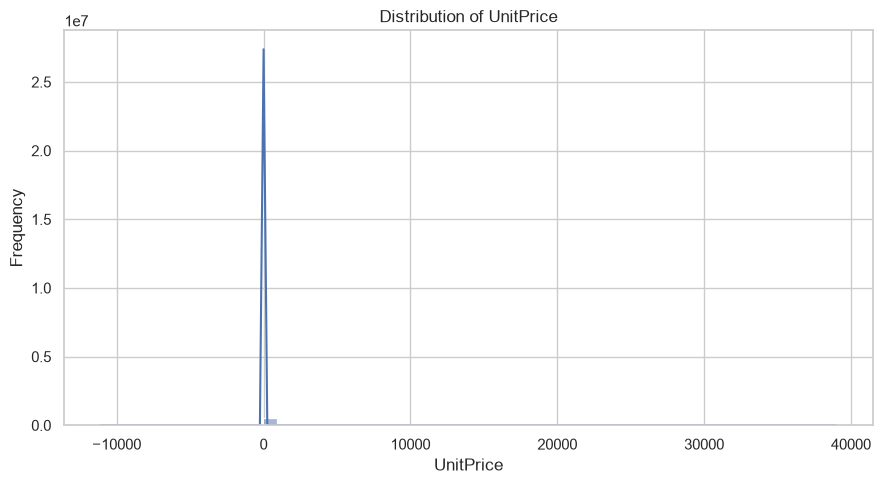

In [14]:
for column in ["Quantity", "UnitPrice"]:
    plt.figure(figsize=(9, 5))

    sns.histplot(
        data=df,
        x=column,
        bins=50,
        kde=True
    )

    plt.title(f"Distribution of {column}")
    plt.xlabel(column)
    plt.ylabel("Frequency")
    plt.tight_layout()
    plt.show()

## Analyze correlations
Correlation helps you investigate whether numerical features move together.

,Quantity,UnitPrice
Quantity,1.000,-0.001
UnitPrice,-0.001,1.000


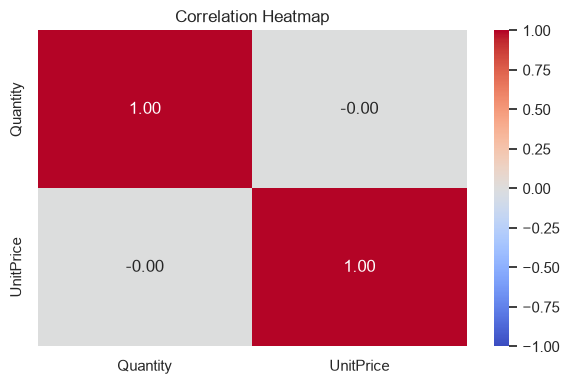

In [15]:
correlation_df = df[["Quantity", "UnitPrice"]].dropna()

correlation_matrix = correlation_df.corr()

display(correlation_matrix.round(3))

plt.figure(figsize=(6, 4))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    fmt=".2f"
)

plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

## Create meaningful visualizations
You have already created histograms, box plots, bar charts, scatter plots, and a heatmap. Now create a time-based visualization to investigate changes across months.

In [16]:
eda_df = df.copy()

eda_df["InvoiceDate"] = pd.to_datetime(
    eda_df["InvoiceDate"],
    errors="coerce"
)

eda_df["LineValue"] = (
    eda_df["Quantity"] * eda_df["UnitPrice"]
)

eda_df["InvoiceMonth"] = (
    eda_df["InvoiceDate"].dt.to_period("M")
)

## Identify important patterns
At this stage, combine the evidence from your tables, statistics, and visualizations.

In [18]:
eda_df["LineValue"] = eda_df["Quantity"] * eda_df["UnitPrice"]

country_summary = (
    eda_df.groupby("Country")
    .agg(
        RecordCount=("InvoiceNo", "size"),
        TotalQuantity=("Quantity", "sum"),
        TotalLineValue=("LineValue", "sum")
    )
    .sort_values("RecordCount", ascending=False)
)

display(country_summary.head(10))

,RecordCount,TotalQuantity,TotalLineValue
Country,,,
United Kingdom,495478,4263829,8187806.364
Germany,9495,117448,221698.210
France,8557,110480,197403.900
EIRE,8196,142637,263276.820
Spain,2533,26824,54774.580
Netherlands,2371,200128,284661.540
Belgium,2069,23152,40910.960
Switzerland,2002,30325,56385.350
Portugal,1519,16180,29367.020
